# 実験11 (ex011): 局所更新ステップ数 $\tau$ の影響・Non-IID度 $\beta$ 耐性の全11手法 × 10シード検証

論文 Figure 9（$\tau \in \{1, 10, 20, 30, 40, 50\}$）および `fedsso/ex003`（$\beta \in \{0.05, 0.2, 1.0, \mathrm{IID}\}$）の条件を、全 11 手法・10 シード・200 ラウンドへ拡張して比較します。

In [1]:
import os
import torch
import pandas as pd
from model import verify_batched_mclr_equivalence
from utils import (
    DEFAULT_SEEDS, load_and_partition_mnist, run_11a_local_steps_study, run_11b_non_iid_study,
    plot_11a_local_steps, plot_11b_non_iid, plot_filtered_11a_tau, plot_filtered_11b_non_iid,
)

device = "cuda" if torch.cuda.is_available() else "cpu"
clients, packed, _, _, _, _ = load_and_partition_mnist("../datasets", seed=42, device=device)
max_diff = verify_batched_mclr_equivalence(clients, packed, tau=5, batch_size=100, lr=0.001, device=device)
print(f"使用デバイス: {device} | 並列SGD最大誤差: {max_diff:.3e}")

使用デバイス: cuda | 並列SGD最大誤差: 1.118e-08


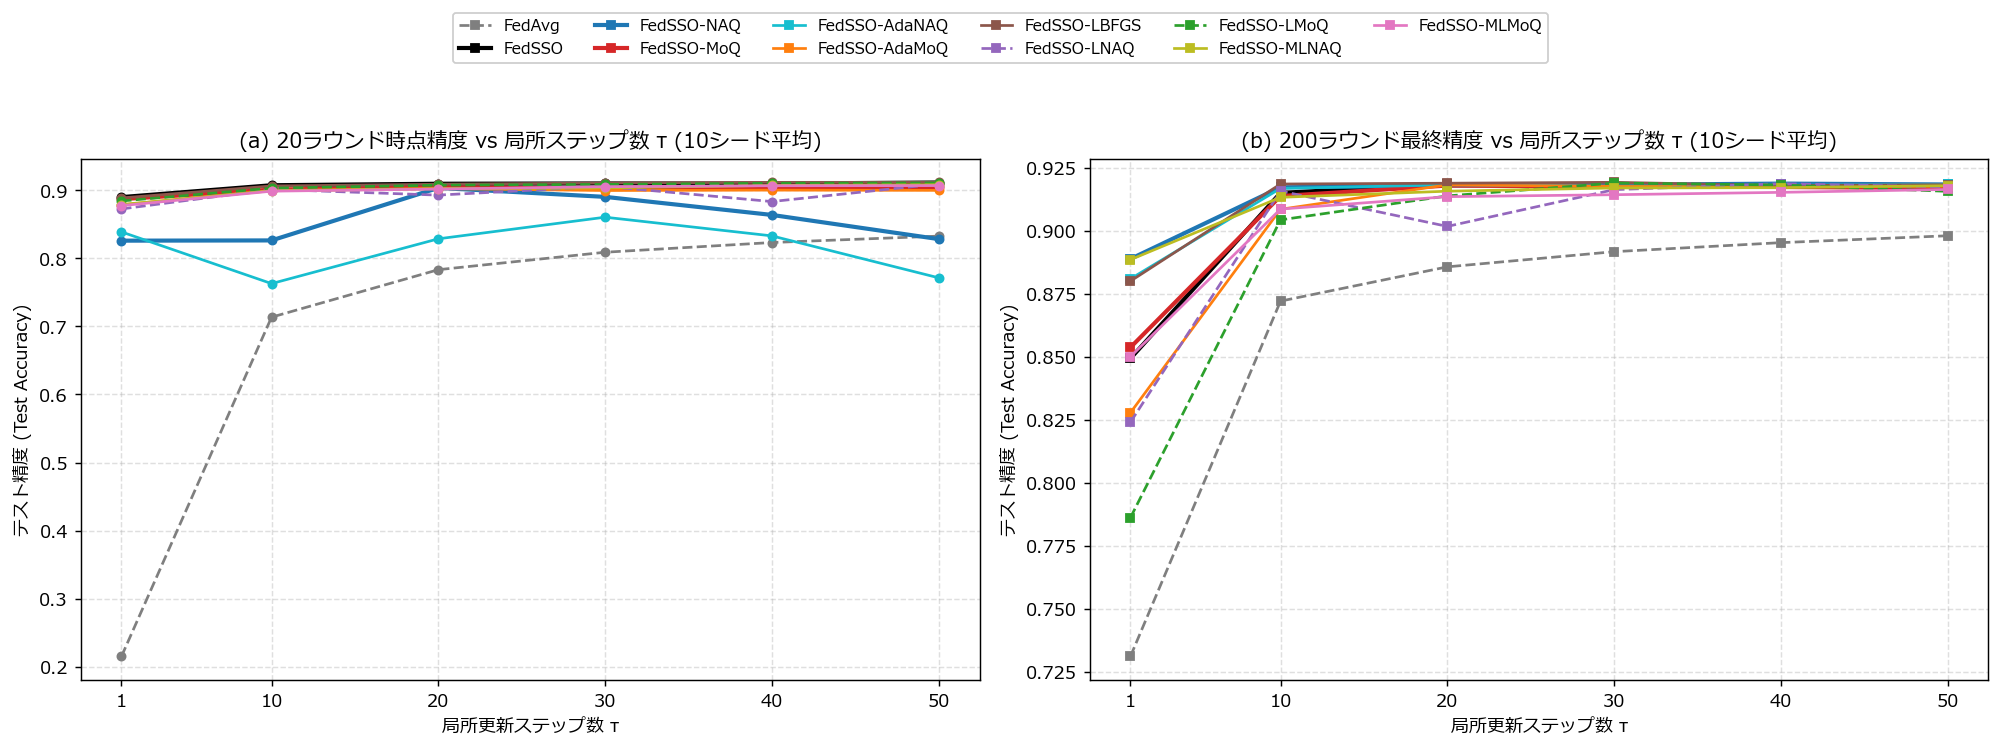

,Algorithm,tau,Seeds,Acc20_Ave,Acc50_Ave,Acc_Ave,Acc_Best,Acc_Worst,Acc_Std,Loss_Ave,Clip_Ave
0,FedAvg,1,10,0.214949,0.412864,0.730990,0.741775,0.719516,0.008792,1.185170,0.0
1,FedAvg,10,10,0.713677,0.813120,0.872152,0.875992,0.868102,0.002251,0.493582,0.0
2,FedAvg,20,10,0.783481,0.845015,0.885769,0.889244,0.880784,0.002482,0.419550,0.0
3,FedAvg,30,10,0.809122,0.858689,0.891795,0.895470,0.886496,0.002475,0.388602,0.0
4,FedAvg,40,10,0.823424,0.865749,0.895388,0.899240,0.890323,0.002603,0.370648,0.0
5,FedAvg,50,10,0.832849,0.870998,0.898118,0.901525,0.893751,0.002244,0.358552,0.0
6,FedSSO,1,10,0.890173,0.908970,0.849371,0.900331,0.732393,0.057924,0.472546,0.0
7,FedSSO,10,10,0.907617,0.917852,0.915174,0.921688,0.894734,0.007503,0.246840,0.0
8,FedSSO,20,10,0.909827,0.918983,0.918526,0.922774,0.916429,0.001809,0.231344,0.0
9,FedSSO,30,10,0.910239,0.919177,0.918184,0.922317,0.915515,0.001782,0.229626,0.0


In [2]:
sum_11a, ps_11a = run_11a_local_steps_study(data_dir="../datasets", seeds=DEFAULT_SEEDS, rounds=200, device=device)
os.makedirs("../report/img", exist_ok=True)
plot_11a_local_steps(sum_11a, save_path="../report/img/ex011_local_steps_impact.png")
sum_11a.head(18)

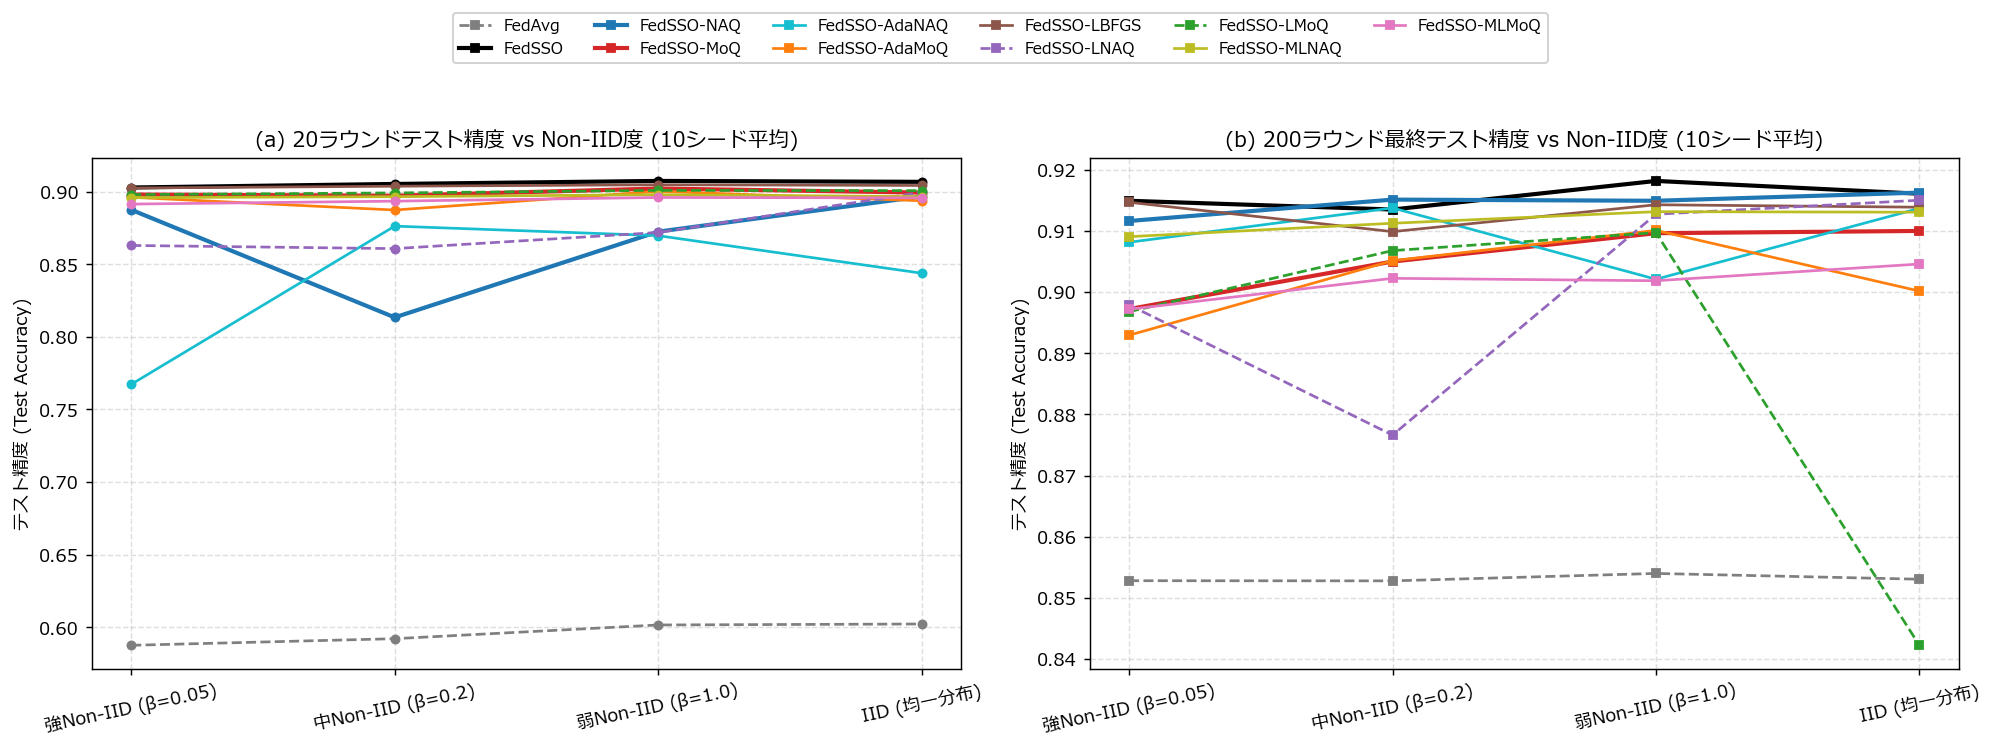

,Distribution,Algorithm,Seeds,Acc20_Ave,Acc100_Ave,Acc_Ave,Acc_Best,Acc_Worst,Acc_Std,Loss_Ave,Clip_Ave
0,強Non-IID (β=0.05),FedAvg,10,0.587539,0.817566,0.852803,0.855658,0.847279,0.002792,0.614073,0.0
1,強Non-IID (β=0.05),FedSSO,10,0.902908,0.918479,0.914926,0.924430,0.905072,0.006347,0.262635,0.0
2,強Non-IID (β=0.05),FedSSO-NAQ,10,0.887543,0.913738,0.911619,0.918257,0.905980,0.004273,0.268926,0.0
3,強Non-IID (β=0.05),FedSSO-MoQ,10,0.898076,0.918827,0.897219,0.920603,0.849269,0.024632,0.312324,0.0
4,強Non-IID (β=0.05),FedSSO-AdaNAQ,10,0.767329,0.909180,0.908140,0.916829,0.896499,0.007176,0.287300,0.0
5,強Non-IID (β=0.05),FedSSO-AdaMoQ,10,0.896168,0.918930,0.892940,0.912721,0.872158,0.015055,0.323352,0.0
6,強Non-IID (β=0.05),FedSSO-LBFGS,10,0.902560,0.918827,0.914680,0.922317,0.906437,0.005600,0.271899,0.0
7,強Non-IID (β=0.05),FedSSO-LNAQ,10,0.862986,0.913938,0.897899,0.915929,0.843254,0.026426,0.341310,0.0
8,強Non-IID (β=0.05),FedSSO-LMoQ,10,0.898013,0.917416,0.896785,0.919347,0.837731,0.023450,0.327360,0.2
9,強Non-IID (β=0.05),FedSSO-MLNAQ,10,0.895911,0.913401,0.909060,0.915805,0.903981,0.004115,0.324081,75.7


In [3]:
sum_11b, ps_11b = run_11b_non_iid_study(data_dir="../datasets", seeds=DEFAULT_SEEDS, rounds=200, device=device)
plot_11b_non_iid(sum_11b, save_path="../report/img/ex011_non_iid_robustness.png")
sum_11b

## 特定のシード値・アルゴリズムに絞ったグラフ表示（実験 11A・11B）

保存済みシード別 CSV から任意のアルゴリズム・シード値だけを指定して再描画できます。

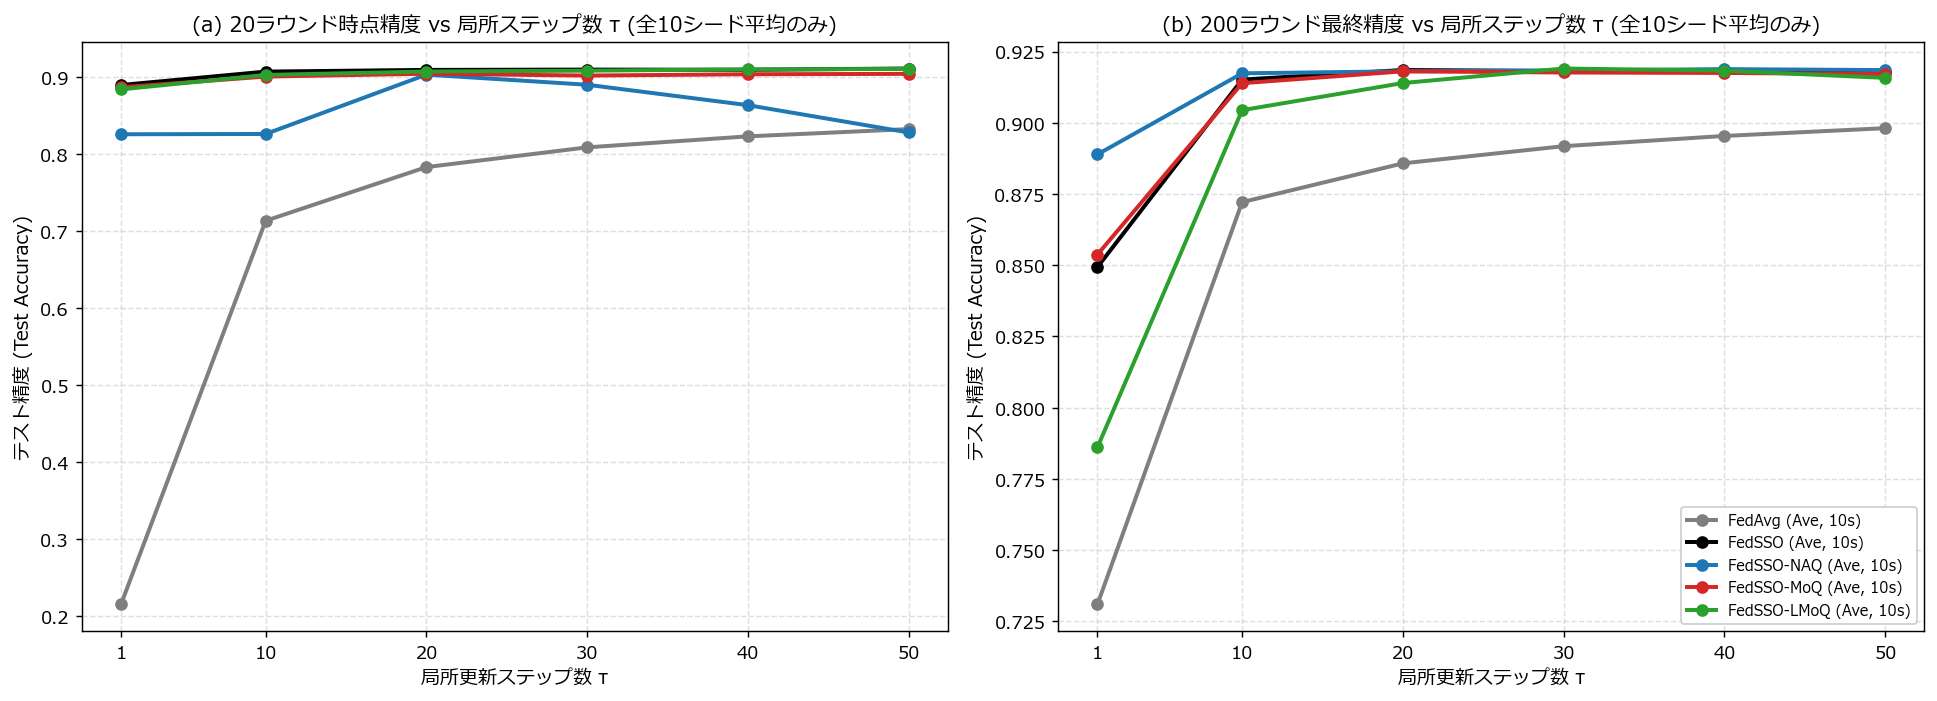

,Algorithm,tau,Seeds,Acc20_Ave,Acc_Ave,Loss_Ave
0,FedAvg,1,10,0.214949,0.730990,1.185170
1,FedAvg,10,10,0.713677,0.872152,0.493582
2,FedAvg,20,10,0.783481,0.885769,0.419550
3,FedAvg,30,10,0.809122,0.891795,0.388602
4,FedAvg,40,10,0.823424,0.895388,0.370648
5,FedAvg,50,10,0.832849,0.898118,0.358552
6,FedSSO,1,10,0.890173,0.849371,0.472546
7,FedSSO,10,10,0.907617,0.915174,0.246840
8,FedSSO,20,10,0.909827,0.918526,0.231344
9,FedSSO,30,10,0.910239,0.918184,0.229626


In [4]:
# ここを変更して特定のシード値・アルゴリズムのグラフを表示（実験 11A: 局所更新ステップ数 τ）
SELECTED_ALGOS_11A = ["FedAvg", "FedSSO", "FedSSO-NAQ", "FedSSO-MoQ", "FedSSO-LMoQ"]
SELECTED_SEEDS_11A = None    # None で全10シード対象（例: [42, 46] で特定シードに絞り込み）
SHOW_MEAN_11A = True
PLOT_MEAN_ONLY_11A = "auto"  # "auto": SELECTED_SEEDS_11A=None 時に平均線のみ描画 / True / False
TABLE_MEAN_ONLY_11A = "auto" # "auto": SELECTED_SEEDS_11A=None 時に平均のみの行を出力 / True / False

df_11a_filtered = plot_filtered_11a_tau(
    selected_algos=SELECTED_ALGOS_11A,
    selected_seeds=SELECTED_SEEDS_11A,
    per_seed_csv_path="../datasets/ex011_local_steps_per_seed.csv",
    show_mean=SHOW_MEAN_11A,
    plot_mean_only=PLOT_MEAN_ONLY_11A,
    table_mean_only=TABLE_MEAN_ONLY_11A,
)
df_11a_filtered

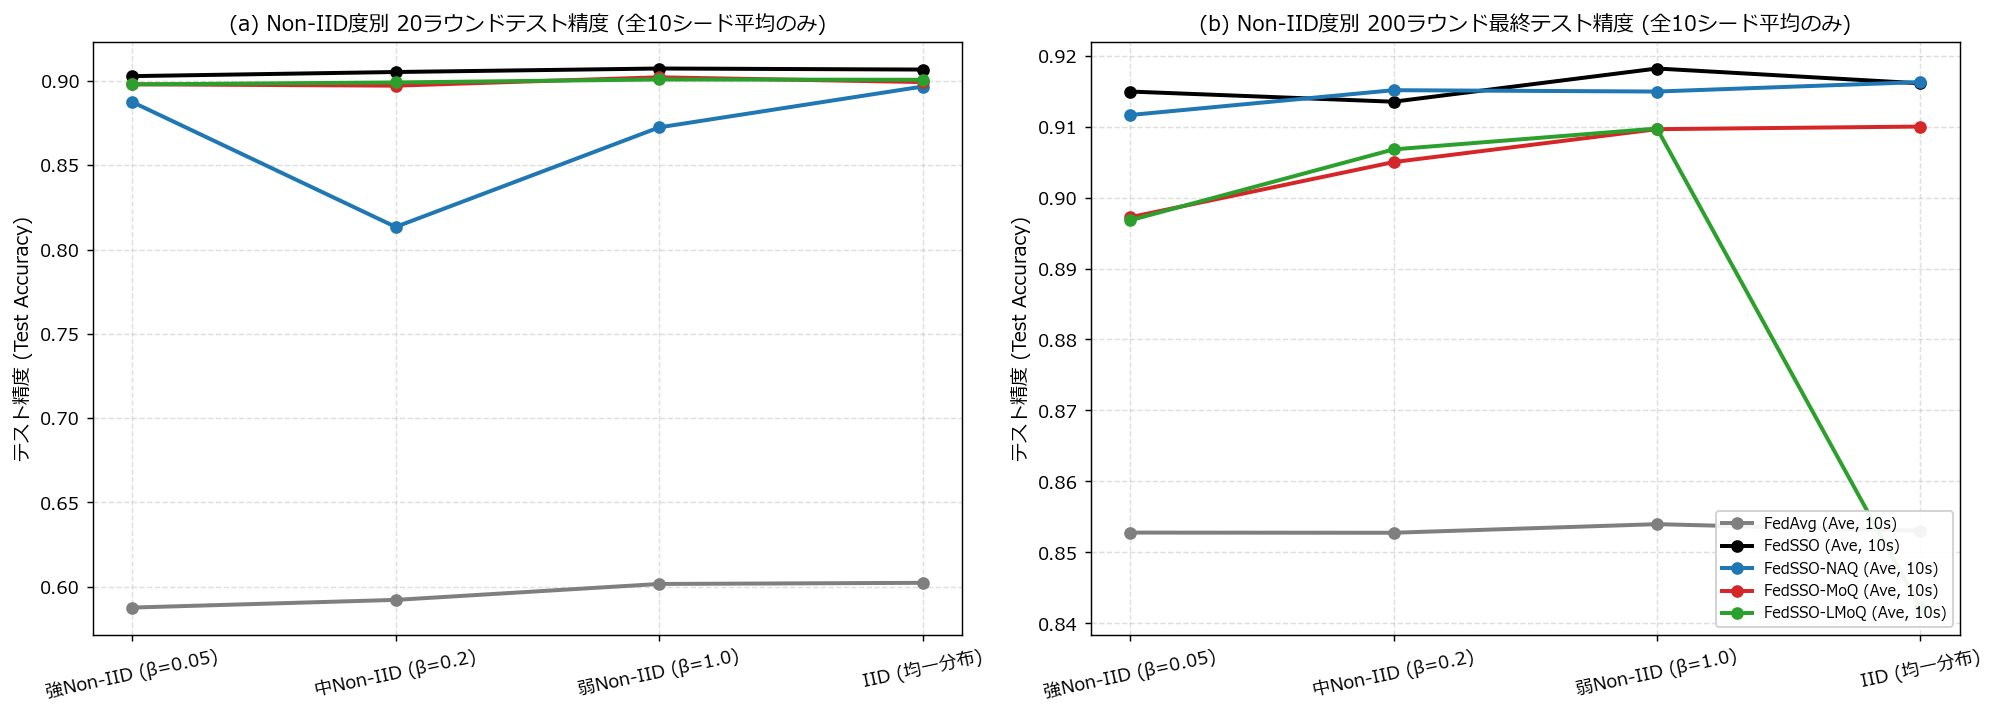

,Distribution,Algorithm,Seeds,Acc20_Ave,Acc_Ave,Loss_Ave
0,強Non-IID (β=0.05),FedAvg,10,0.587539,0.852803,0.614073
1,強Non-IID (β=0.05),FedSSO,10,0.902908,0.914926,0.262635
2,強Non-IID (β=0.05),FedSSO-NAQ,10,0.887543,0.911619,0.268926
3,強Non-IID (β=0.05),FedSSO-MoQ,10,0.898076,0.897219,0.312324
4,強Non-IID (β=0.05),FedSSO-LMoQ,10,0.898013,0.896785,0.327360
5,中Non-IID (β=0.2),FedAvg,10,0.592100,0.852777,0.606156
6,中Non-IID (β=0.2),FedSSO,10,0.905349,0.913494,0.259679
7,中Non-IID (β=0.2),FedSSO-NAQ,10,0.813427,0.915116,0.258485
8,中Non-IID (β=0.2),FedSSO-MoQ,10,0.897244,0.904990,0.287222
9,中Non-IID (β=0.2),FedSSO-LMoQ,10,0.899163,0.906777,0.296374


In [5]:
# ここを変更して特定のシード値・アルゴリズムのグラフを表示（実験 11B: Non-IID度 β 耐性）
SELECTED_ALGOS_11B = ["FedAvg", "FedSSO", "FedSSO-NAQ", "FedSSO-MoQ", "FedSSO-LMoQ"]
SELECTED_SEEDS_11B = None    # None で全10シード対象（例: [42, 46] で特定シードに絞り込み）
SHOW_MEAN_11B = True
PLOT_MEAN_ONLY_11B = "auto"  # "auto": SELECTED_SEEDS_11B=None 時に平均線のみ描画 / True / False
TABLE_MEAN_ONLY_11B = "auto" # "auto": SELECTED_SEEDS_11B=None 時に平均のみの行を出力 / True / False

df_11b_filtered = plot_filtered_11b_non_iid(
    selected_algos=SELECTED_ALGOS_11B,
    selected_seeds=SELECTED_SEEDS_11B,
    per_seed_csv_path="../datasets/ex011_non_iid_per_seed.csv",
    show_mean=SHOW_MEAN_11B,
    plot_mean_only=PLOT_MEAN_ONLY_11B,
    table_mean_only=TABLE_MEAN_ONLY_11B,
)
df_11b_filtered